In [ ]:
!python -m spacy download es_core_news_sm

  Using cached https://github.com/explosion/spacy-models/releases/download/es_core_news_sm-3.8.0/es_core_news_sm-3.8.0-py3-none-any.whl (12.9 MB)
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Columnas encontradas: ['Resumen', 'Introduccion', 'Conclusiones']

INICIANDO PROCESAMIENTO DEL CORPUS

PASO 1: PREPROCESAMIENTO


Preprocesando: 100%|██████████| 52/52 [00:20<00:00,  2.55it/s]



✓ Preprocesamiento completado

PASO 2: ETIQUETADO POS Y ANÁLISIS MORFOSINTÁCTICO


Etiquetado POS: 100%|██████████| 52/52 [00:11<00:00,  4.56it/s]



✓ Etiquetado POS completado

PASO 3: VECTORIZACIÓN TF-IDF

📊 Analizando columna: Resumen
  - Total de textos: 52
  - Longitud promedio: 191.8 palabras
  - Texto ejemplo (primeras 50 palabras): el presente artículo investiga los efectos de un programa psicoeducativo diseñado mediante episodios del programa de televisión barrio sésamo en el desarrollo de la creatividad infantil en educación i...
  ⚠️ TF-IDF tradicional falló, usando método alternativo: The 'stop_words' parameter of TfidfVectorizer must
  ✓ Palabras clave encontradas: 20
  ✓ Top 3: ['creatividad', 'pensamiento', 'trabajo']

📊 Analizando columna: Introduccion
  - Total de textos: 52
  - Longitud promedio: 410.1 palabras
  - Texto ejemplo (primeras 50 palabras): la creatividad en la infancia constituye una competencia fundamental para el desarrollo integral, ya que no solo favorece la generación de ideas originales y la flexibilidad cognitiva, sino que tambié...
  ⚠️ TF-IDF tradicional falló, usando método alternativo: The

Análisis sintáctico: 100%|██████████| 52/52 [00:08<00:00,  6.27it/s]



✓ Análisis sintáctico completado

RESULTADOS GLOBALES

📊 DISTRIBUCIÓN POS TAGS GLOBAL:
----------------------------------------------------------------------
  NOUN..........................  11764 ( 28.3%)
  DET...........................   6529 ( 15.7%)
  ADJ...........................   6223 ( 15.0%)
  ADP...........................   5561 ( 13.4%)
  VERB..........................   4316 ( 10.4%)
  CCONJ.........................   2092 (  5.0%)
  PRON..........................   1539 (  3.7%)
  SCONJ.........................   1113 (  2.7%)
  ADV...........................   1025 (  2.5%)
  AUX...........................    632 (  1.5%)
  PROPN.........................    363 (  0.9%)
  SPACE.........................    269 (  0.6%)
  PART..........................     96 (  0.2%)
  NUM...........................     49 (  0.1%)
  INTJ..........................      1 (  0.0%)

📊 ESTRUCTURAS SINTÁCTICAS:
----------------------------------------------------------------------
  NOUN_

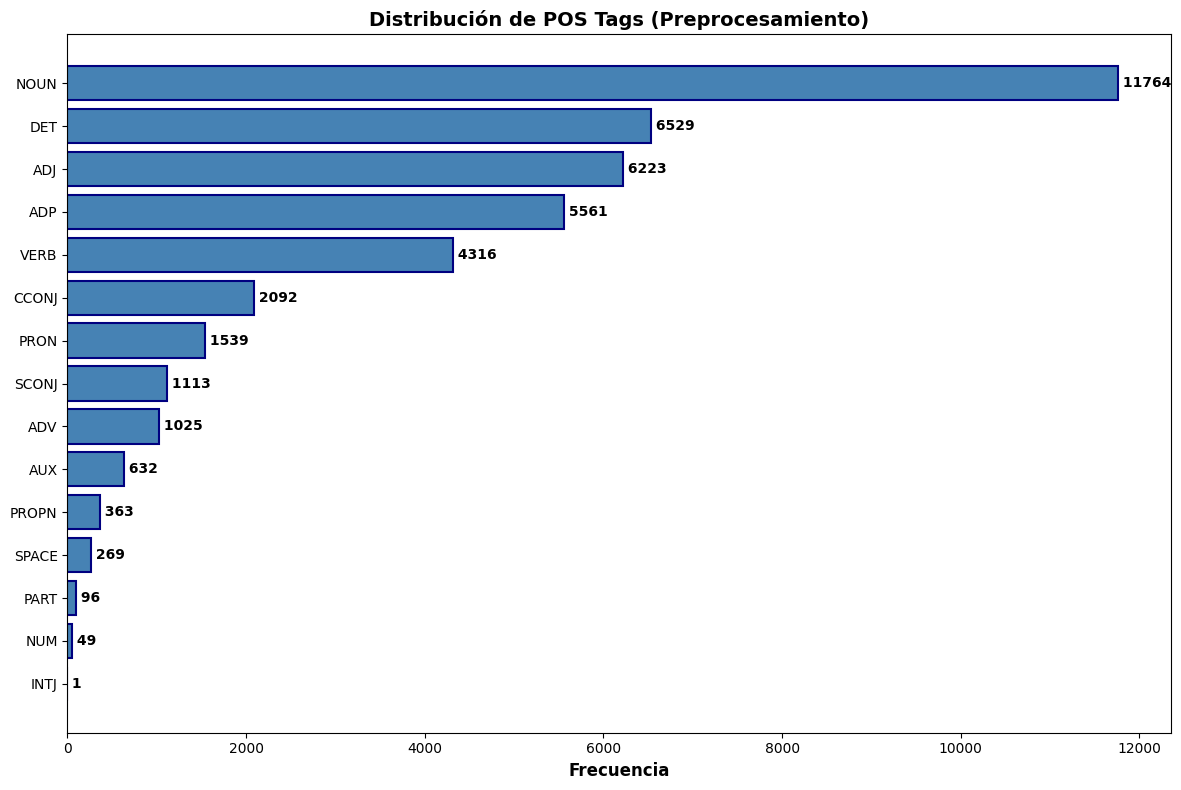

✓ Gráfico 1: 01_preprocesamiento_pos_tags.png


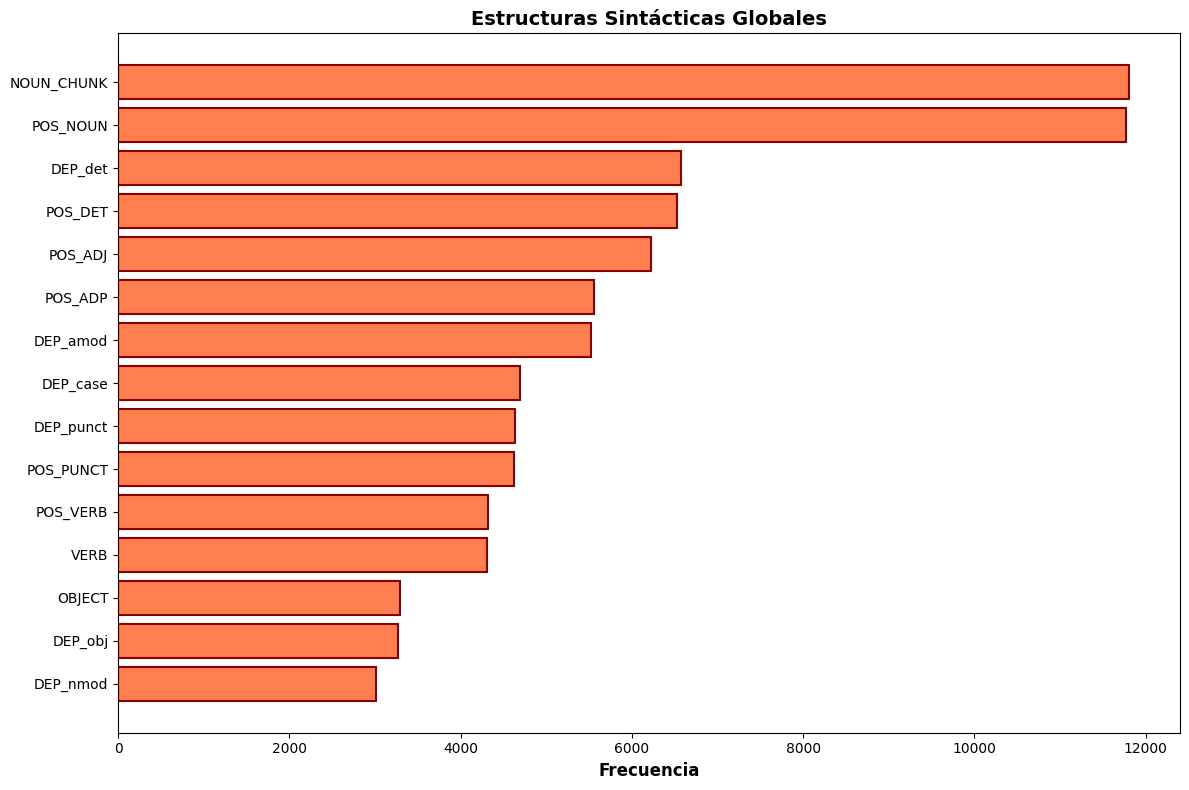

✓ Gráfico 2: 02_analisis_sintactico_global.png


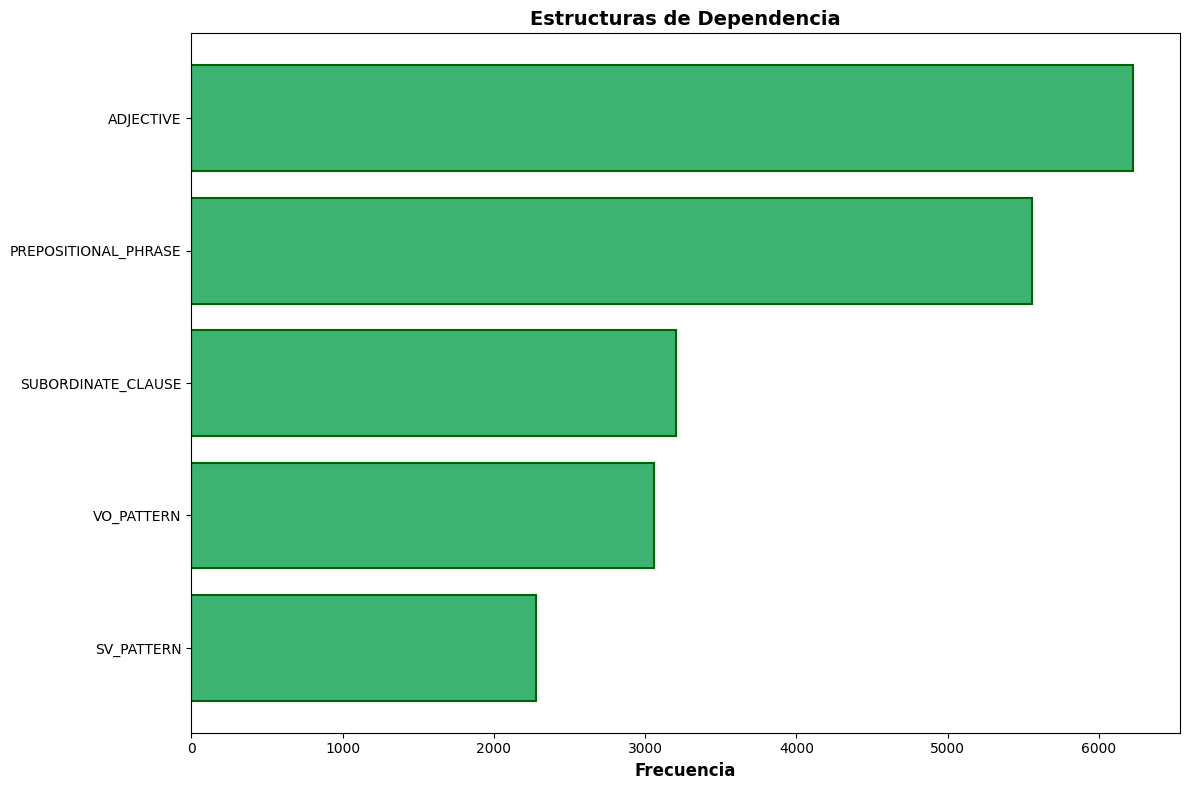

✓ Gráfico 3: 03_analisis_dependencias.png


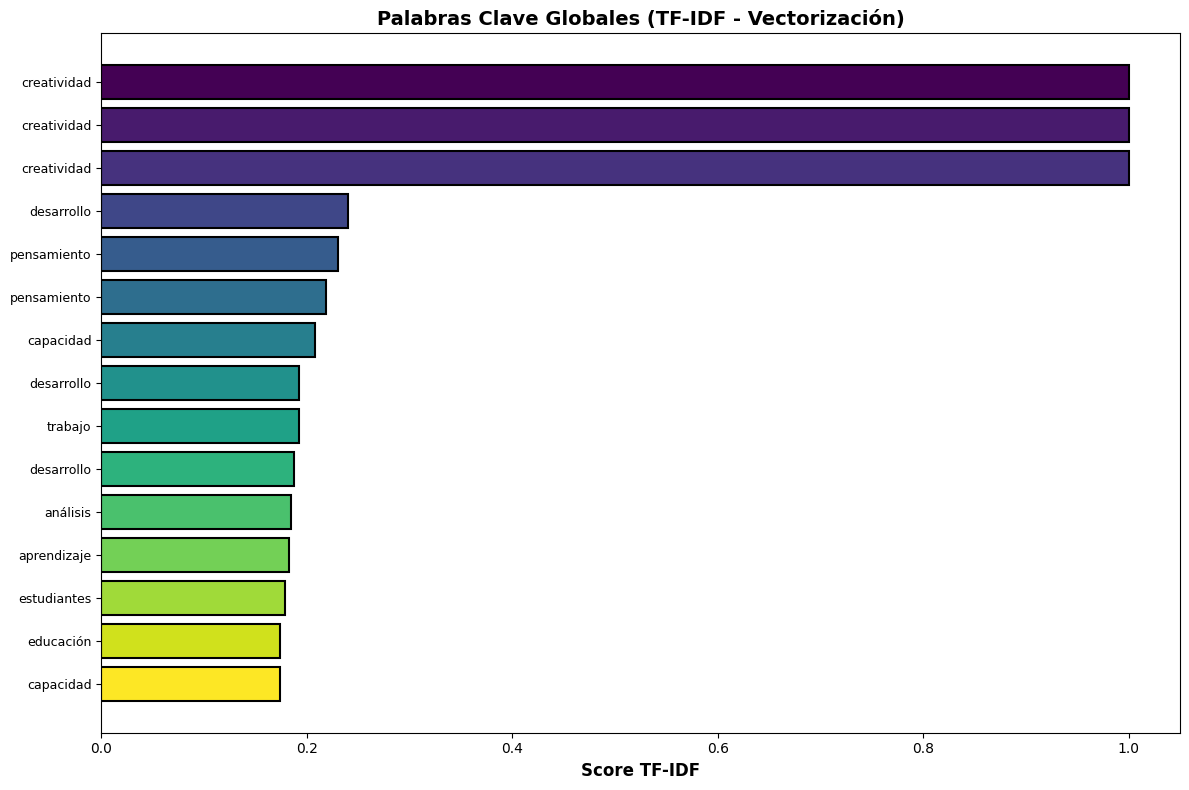

✓ Gráfico 4: 04_vectorizacion_tfidf.png


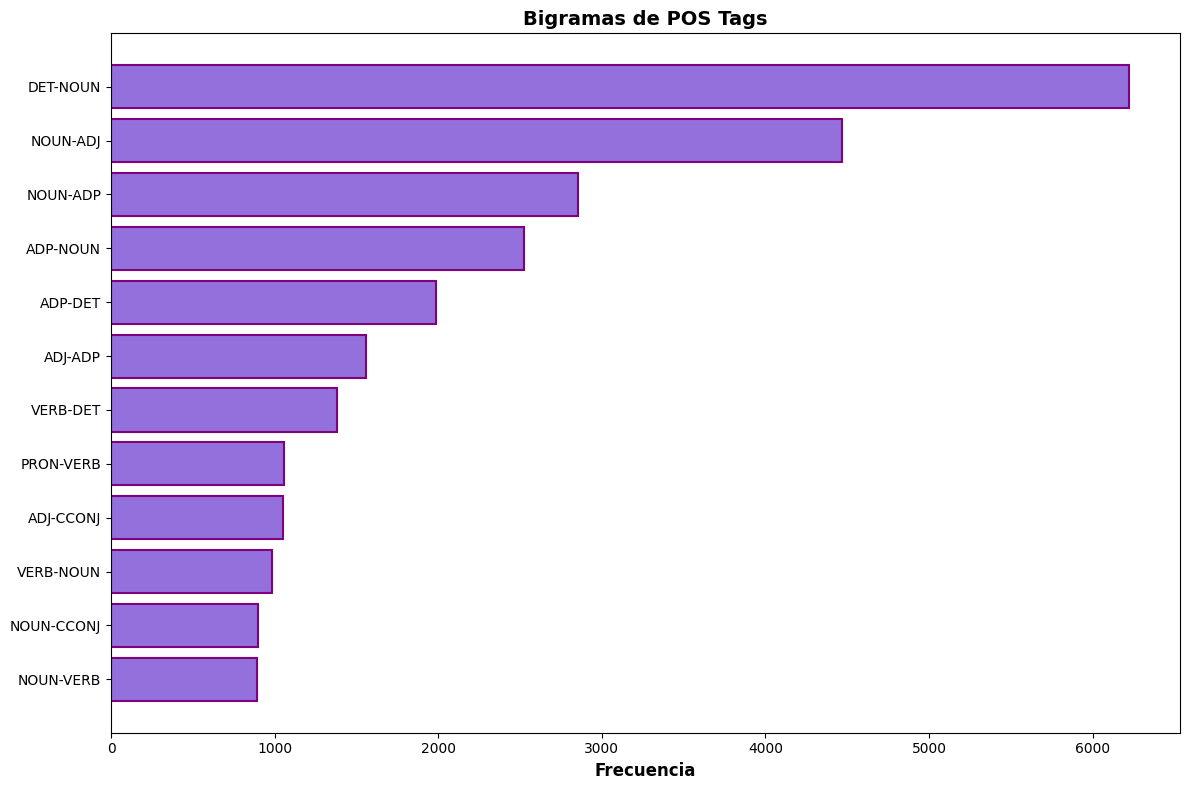

✓ Gráfico 5: 05_analisis_bigramas.png


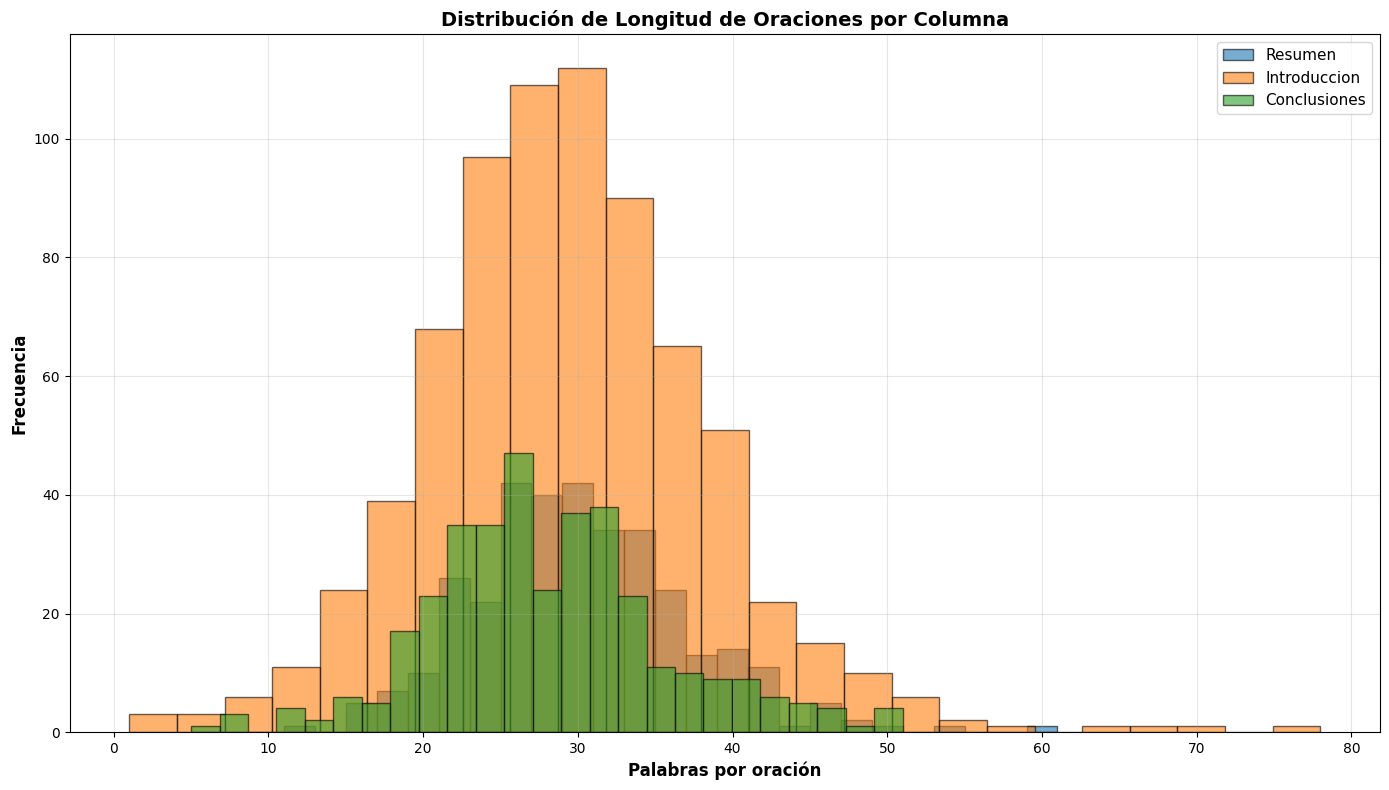

✓ Gráfico 6: 06_longitud_oraciones_comparacion.png


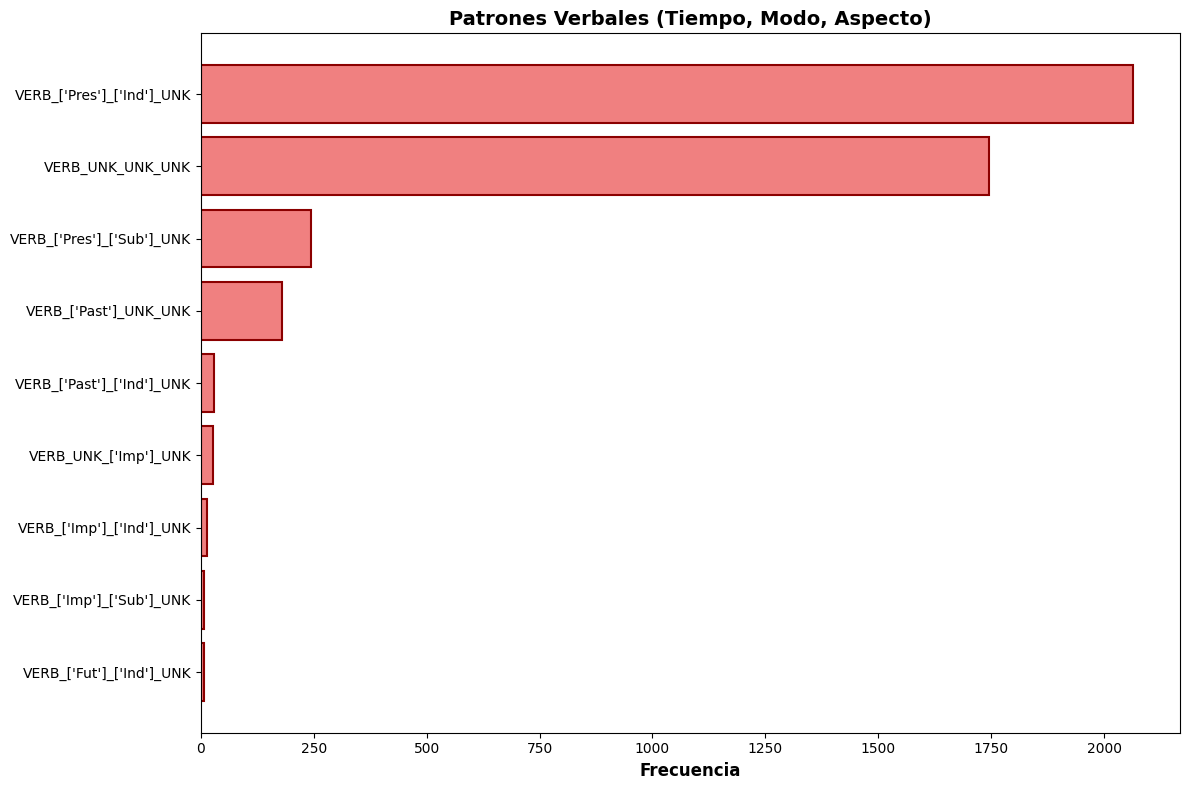

✓ Gráfico 7: 07_patrones_verbales.png


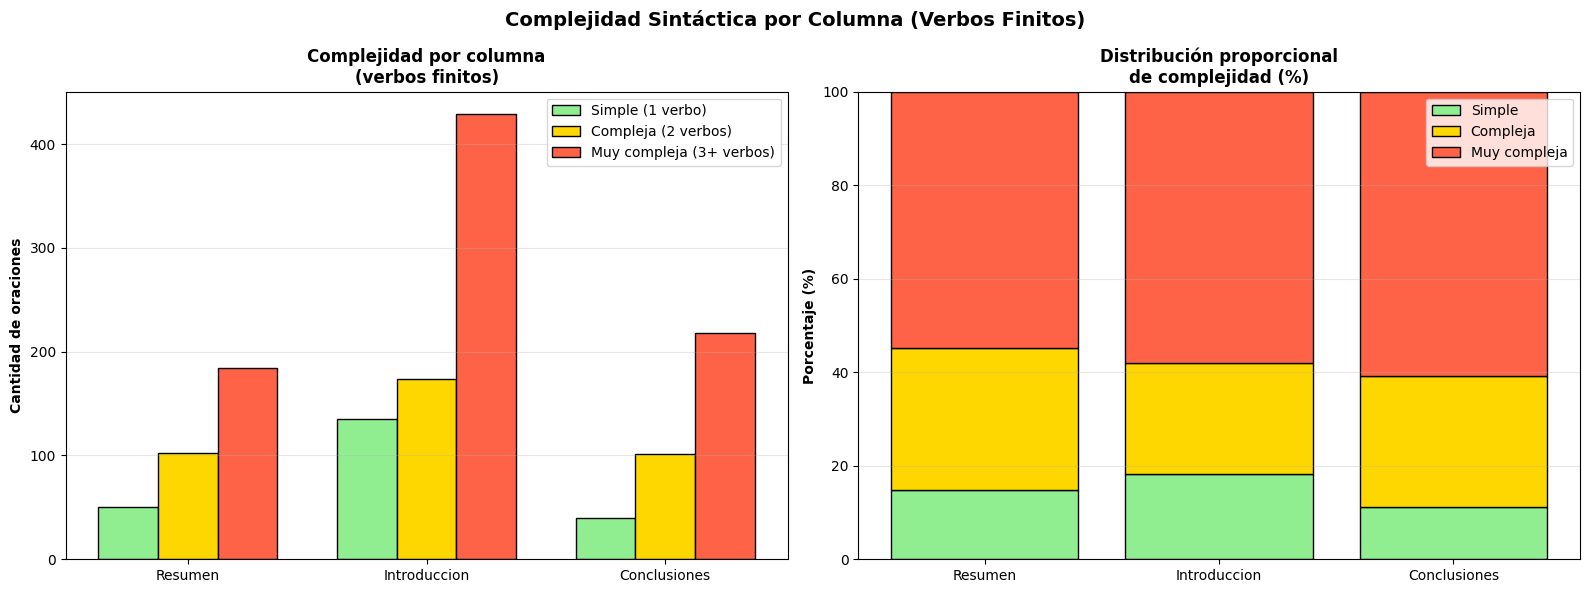

✓ Gráfico 8: 08_subordinacion_por_columna.png

EXPORTANDO RESULTADOS

✓ Archivos CSV exportados:
  - 01_analisis_pos_tags.csv
  - 02_estructuras_sintacticas.csv
  - 03_tfidf_Resumen.csv
  - 03_tfidf_Introduccion.csv
  - 03_tfidf_Conclusiones.csv
  - 04_patrones_verbales.csv
  - 05_analisis_detallado.csv
  - 05_analisis_bigramas.png
  - 06_longitud_oraciones_comparacion.png
  - 07_patrones_verbales.png
  - 08_subordinacion_por_columna.png

✅ ANÁLISIS COMPLETADO EXITOSAMENTE

Pipeline completo ejecutado:
1. ✓ Preprocesamiento (Tokenización, Normalización, Lematización)
2. ✓ Etiquetado Morfosintáctico (POS Tagging)
3. ✓ Vectorización (TF-IDF)
4. ✓ Análisis Sintáctico (Dependencias, N-gramas, Patrones)
5. ✓ Análisis Adicionales y Visualizaciones



In [ ]:
import pandas as pd
import spacy
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from tqdm import tqdm
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Instalar y cargar modelo de español
# !python -m spacy download es_core_news_sm

nlp = spacy.load("es_core_news_sm")

# ========================
# 0. CARGAR EL ARCHIVO
# ========================
df = pd.read_excel('/content/Corpus_humano.xlsx')

COLUMNS_TO_ANALYZE = ['Resumen', 'Introduccion', 'Conclusiones']
available_cols = [col for col in COLUMNS_TO_ANALYZE if col in df.columns]
print(f"Columnas encontradas: {available_cols}\n")

# ========================
# 1. PREPROCESAMIENTO DEL TEXTO
# ========================

def preprocess_text(text):
    """
    Preprocesamiento completo:
    - Tokenización (spaCy)
    - Normalización (minúsculas, espacios)
    - Lematización (root de palabras)
    """
    if not text or not isinstance(text, str):
        return "", [], []

    # Normalización básica
    text = str(text).lower()
    text = re.sub(r'\s+', ' ', text)  # Espacios múltiples
    text = text.strip()

    # Procesar con spaCy (tokenización + lematización automática)
    doc = nlp(text)

    # Extraer tokens lematizados
    lemmatized_tokens = [token.lemma_ for token in doc if not token.is_punct and not token.is_space]

    # Extraer tokens sin lematizar (originales)
    original_tokens = [token.text for token in doc if not token.is_punct and not token.is_space]

    return text, lemmatized_tokens, original_tokens

# ========================
# 2. ETIQUETADO MORFOSINTÁCTICO (POS)
# ========================

def pos_tagging_analysis(doc):
    """Análisis completo de etiquetado POS"""
    pos_counts = defaultdict(int)
    pos_details = []

    for token in doc:
        if not token.is_punct:
            pos_counts[token.pos_] += 1
            pos_details.append({
                'token': token.text,
                'lemma': token.lemma_,
                'pos': token.pos_,
                'tag': token.tag_,
                'dep': token.dep_
            })

    return dict(pos_counts), pos_details

# ========================
# 3. VECTORIZACIÓN (TF-IDF)
# ========================

def tfidf_analysis(texts_list, top_n=15):
    """
    Análisis TF-IDF completo con fallback a frecuencia simple
    - Calcula importancia de cada término
    - Identifica palabras clave
    """
    if not texts_list or len(texts_list) < 1:
        return {}, []

    # Filtrar textos vacíos
    texts_list = [str(t).strip() for t in texts_list if t and len(str(t).strip()) > 5]

    if not texts_list:
        return {}, []

    # MÉTODO 1: Intentar TF-IDF tradicional
    try:
        vectorizer = TfidfVectorizer(
            max_features=50,
            stop_words='spanish',
            ngram_range=(1, 2),
            min_df=1,
            max_df=0.95,
            lowercase=True,
            token_pattern=r'(?u)\b\w\w+\b'  # Palabras de 2+ caracteres
        )

        tfidf_matrix = vectorizer.fit_transform(texts_list)
        feature_names = vectorizer.get_feature_names_out()

        if len(feature_names) == 0:
            raise ValueError("No features extracted")

        # Calcular scores promedio
        scores = np.asarray(tfidf_matrix.mean(axis=0)).ravel()

        # Top palabras clave
        top_indices = scores.argsort()[-top_n:][::-1]
        keywords_dict = {
            feature_names[idx]: float(scores[idx])
            for idx in top_indices if scores[idx] > 0
        }

        # Matriz completa de TF-IDF por documento
        tfidf_data = []
        for doc_idx, doc_scores in enumerate(tfidf_matrix.toarray()):
            top_doc_indices = doc_scores.argsort()[-5:][::-1]
            doc_keywords = [feature_names[idx] for idx in top_doc_indices if doc_scores[idx] > 0]
            if doc_keywords:
                tfidf_data.append({
                    'documento': doc_idx,
                    'palabras_clave': doc_keywords
                })

        if keywords_dict:  # Si TF-IDF funcionó
            return keywords_dict, tfidf_data
        else:
            raise ValueError("Empty keywords")

    except Exception as e:
        print(f"  ⚠️ TF-IDF tradicional falló, usando método alternativo: {str(e)[:50]}")

    # MÉTODO 2: Fallback - Frecuencia ponderada por POS
    try:
        keywords_dict = defaultdict(float)

        for text in texts_list:
            doc = nlp(text)

            # Contar palabras importantes por tipo
            for token in doc:
                word = token.text.lower()

                # Filtros
                if token.is_stop or token.is_punct or len(word) < 3:
                    continue

                # Ponderación por POS
                if token.pos_ == 'NOUN':
                    keywords_dict[word] += 3.0
                elif token.pos_ == 'PROPN':
                    keywords_dict[word] += 2.5
                elif token.pos_ == 'VERB':
                    keywords_dict[word] += 2.0
                elif token.pos_ == 'ADJ':
                    keywords_dict[word] += 1.5
                else:
                    keywords_dict[word] += 1.0

        if not keywords_dict:
            return {}, []

        # Normalizar scores
        max_score = max(keywords_dict.values()) if keywords_dict else 1
        keywords_dict = {k: v/max_score for k, v in keywords_dict.items()}

        # Top N
        sorted_keywords = sorted(keywords_dict.items(), key=lambda x: x[1], reverse=True)[:top_n]
        keywords_dict = dict(sorted_keywords)

        # Crear estructura de datos compatible
        tfidf_data = []
        for idx in range(min(len(texts_list), 10)):  # Primeros 10 docs
            doc_keywords = list(keywords_dict.keys())[:5]
            tfidf_data.append({
                'documento': idx,
                'palabras_clave': doc_keywords
            })

        return keywords_dict, tfidf_data

    except Exception as e:
        print(f"  ⚠️ Método alternativo también falló: {str(e)}")
        return {}, []

# ========================
# 4. ANÁLISIS SINTÁCTICO
# ========================

def syntactic_analysis(doc):
    """Análisis sintáctico completo: estructuras, dependencias"""

    # Patrones sintácticos
    syntactic_patterns = defaultdict(int)

    # Contar POS tags
    for token in doc:
        syntactic_patterns[f"POS_{token.pos_}"] += 1

    # Contar frases nominales
    for chunk in doc.noun_chunks:
        syntactic_patterns["NOUN_CHUNK"] += 1

    # Análisis por oración
    sentence_count = 0
    for sent in doc.sents:
        sentence_count += 1

        # Contar dependencias
        for token in sent:
            syntactic_patterns[f"DEP_{token.dep_}"] += 1

            # Patrones específicos
            if token.dep_ == "nsubj":
                syntactic_patterns["SUBJECT"] += 1
            elif token.dep_ in ["obj", "iobj"]:
                syntactic_patterns["OBJECT"] += 1
            elif token.pos_ == "VERB":
                syntactic_patterns["VERB"] += 1
                if token.head.pos_ in ["AUX", "VERB"]:
                    syntactic_patterns["VERBAL_PHRASE"] += 1

    syntactic_patterns["SENTENCE"] = sentence_count

    return dict(syntactic_patterns)

def dependency_analysis(doc):
    """Análisis de estructuras de dependencia"""
    dep_structures = defaultdict(int)

    for token in doc:
        if token.dep_ == "nsubj" and token.head.pos_ == "VERB":
            dep_structures["SV_PATTERN"] += 1

        if token.dep_ in ["obj", "iobj"] and token.head.pos_ == "VERB":
            dep_structures["VO_PATTERN"] += 1

        if token.pos_ == "ADP":
            dep_structures["PREPOSITIONAL_PHRASE"] += 1

        if token.pos_ == "ADJ":
            dep_structures["ADJECTIVE"] += 1

        if token.pos_ in ["CCONJ", "SCONJ"]:
            dep_structures["SUBORDINATE_CLAUSE"] += 1

    return dict(dep_structures)

def ngram_analysis(doc, n=2):
    """Análisis de n-gramas de POS"""
    tokens = [token.pos_ for token in doc if not token.is_punct]
    ngrams = []

    for i in range(len(tokens) - n + 1):
        ngrams.append(tuple(tokens[i:i+n]))

    return ngrams

def sentence_metrics(doc):
  metrics = {'lengths': [], 'complexity': defaultdict(int),
            'subordination': defaultdict(int)}

  # Por cada oración en el documento
  for sent in doc.sents:
    length = len([t for t in sent if not t.is_punct])
    metrics['lengths'].append(length)

    # ← NUEVO: contar verbos finitos reales
    verb_count = sum(
      1 for token in sent
      if token.pos_ == "VERB"
      and token.dep_ != "aux"
    )

    if verb_count <= 1:
      metrics['subordination']["SIMPLE"] += 1
    elif verb_count == 2:
      metrics['subordination']["COMPLEX"] += 1
    else:
      metrics['subordination']["VERY_COMPLEX"] += 1

  return metrics

# ========================
# 5. PROCESAR CORPUS COMPLETO
# ========================

print("INICIANDO PROCESAMIENTO DEL CORPUS\n")
print("=" * 70)
print("PASO 1: PREPROCESAMIENTO")
print("=" * 70)

row_analysis = []
all_texts = {col: [] for col in available_cols}
all_lemmatized = {col: [] for col in available_cols}

# Preprocesar todos los textos
for idx, row in tqdm(df.iterrows(), total=len(df), desc="Preprocesando"):
    row_data = {"row": idx + 1}

    for col in available_cols:
        text = row[col]

        if pd.isna(text) or text == "":
            continue

        # Preprocesamiento
        norm_text, lemma_tokens, orig_tokens = preprocess_text(text)

        row_data[f"{col}_normalized"] = norm_text
        row_data[f"{col}_lemmas"] = lemma_tokens
        row_data[f"{col}_tokens"] = orig_tokens

        all_texts[col].append(norm_text)
        all_lemmatized[col].extend(lemma_tokens)

    row_analysis.append(row_data)

print("\n✓ Preprocesamiento completado")

print("\n" + "=" * 70)
print("PASO 2: ETIQUETADO POS Y ANÁLISIS MORFOSINTÁCTICO")
print("=" * 70)

global_pos = defaultdict(int)
global_pos_details = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Etiquetado POS"):
    row_data = row_analysis[idx]

    for col in available_cols:
        text = row[col]

        if pd.isna(text) or text == "":
            continue

        doc = nlp(text)
        pos_counts, pos_details = pos_tagging_analysis(doc)

        row_data[f"{col}_pos"] = pos_counts
        row_data[f"{col}_pos_details"] = pos_details

        for pos, count in pos_counts.items():
            global_pos[pos] += count

print("\n✓ Etiquetado POS completado")

print("\n" + "=" * 70)
print("PASO 3: VECTORIZACIÓN TF-IDF")
print("=" * 70)

global_tfidf_keywords = defaultdict(int)
global_tfidf_all = {}

for col in available_cols:
    print(f"\n📊 Analizando columna: {col}")
    texts = [row.get(f"{col}_normalized", "") for row in row_analysis if row.get(f"{col}_normalized")]

    # DIAGNÓSTICO
    print(f"  - Total de textos: {len(texts)}")
    if texts:
        avg_length = np.mean([len(t.split()) for t in texts])
        print(f"  - Longitud promedio: {avg_length:.1f} palabras")
        print(f"  - Texto ejemplo (primeras 50 palabras): {texts[0][:200]}...")

    if not texts:
        print(f"  ⚠️ No hay textos para analizar en esta columna")
        continue

    if len(texts) < 2:
        print(f"  ⚠️ Muy pocos textos ({len(texts)}), TF-IDF puede no funcionar bien")

    keywords_dict, tfidf_data = tfidf_analysis(texts, top_n=20)

    if keywords_dict:
        print(f"  ✓ Palabras clave encontradas: {len(keywords_dict)}")
        print(f"  ✓ Top 3: {list(keywords_dict.keys())[:3]}")

        global_tfidf_all[col] = (keywords_dict, tfidf_data)

        for keyword, score in keywords_dict.items():
            global_tfidf_keywords[f"{col}_{keyword}"] += score

        # Guardar en cada fila
        for idx, tfidf_info in enumerate(tfidf_data):
            if idx < len(row_analysis):
                row_analysis[idx][f"{col}_tfidf"] = tfidf_info
    else:
        print(f"  ❌ No se encontraron palabras clave para esta columna")

print(f"\n✓ Vectorización TF-IDF completada")
print(f"✓ Total de palabras clave únicas: {len(global_tfidf_keywords)}")

print("\n" + "=" * 70)
print("PASO 4: ANÁLISIS SINTÁCTICO COMPLETO")
print("=" * 70)

global_syntactic = defaultdict(int)
global_dependencies = defaultdict(int)
global_bigrams = Counter()
global_trigrams = Counter()
global_sentence_metrics = defaultdict(lambda: {'lengths': [], 'subordination': defaultdict(int)})
global_verb_patterns = defaultdict(int)

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Análisis sintáctico"):
    row_data = row_analysis[idx]

    for col in available_cols:
        text = row[col]

        if pd.isna(text) or text == "":
            continue

        doc = nlp(text)

        # Análisis sintáctico
        syntactic = syntactic_analysis(doc)
        dependencies = dependency_analysis(doc)
        bigrams = ngram_analysis(doc, n=2)
        trigrams = ngram_analysis(doc, n=3)
        sent_metrics = sentence_metrics(doc)

        # Guardar en fila
        row_data[f"{col}_syntactic"] = syntactic
        row_data[f"{col}_dependencies"] = dependencies
        row_data[f"{col}_sent_metrics"] = sent_metrics

        # Acumular globales
        for k, v in syntactic.items():
            global_syntactic[k] += v
        for k, v in dependencies.items():
            global_dependencies[k] += v

        for bigram in bigrams:
            global_bigrams[bigram] += 1
        for trigram in trigrams:
            global_trigrams[trigram] += 1

        global_sentence_metrics[col]['lengths'].extend(sent_metrics['lengths'])
        for subtype, count in sent_metrics['subordination'].items():
            global_sentence_metrics[col]['subordination'][subtype] += count

        # Patrones verbales
        for token in doc:
            if token.pos_ == "VERB":
                morph = token.morph
                tense = morph.get("Tense") or "UNK"
                mood = morph.get("Mood") or "UNK"
                aspect = morph.get("Aspect") or "UNK"
                pattern = f"VERB_{tense}_{mood}_{aspect}"
                global_verb_patterns[pattern] += 1

print("\n✓ Análisis sintáctico completado")

# ========================
# 6. REPORTES Y RESULTADOS
# ========================

print("\n" + "=" * 70)
print("RESULTADOS GLOBALES")
print("=" * 70)

print("\n📊 DISTRIBUCIÓN POS TAGS GLOBAL:")
print("-" * 70)
for pos, count in Counter(global_pos).most_common(15):
    pct = (count / sum(global_pos.values()) * 100)
    print(f"  {pos:.<30} {count:>6} ({pct:>5.1f}%)")

print("\n📊 ESTRUCTURAS SINTÁCTICAS:")
print("-" * 70)
for struct, count in Counter(global_syntactic).most_common(15):
    print(f"  {struct:.<50} {count:>6}")

print("\n📊 ESTRUCTURAS DE DEPENDENCIA:")
print("-" * 70)
for dep, count in Counter(global_dependencies).most_common(12):
    print(f"  {dep:.<50} {count:>6}")

print("\n🔑 PALABRAS CLAVE GLOBALES (TF-IDF):")
print("-" * 70)
tfidf_global = Counter(global_tfidf_keywords)
for keyword, score in tfidf_global.most_common(15):
    print(f"  {keyword:.<50} {score:>8.2f}")

print("\n⚙️ PATRONES VERBALES:")
print("-" * 70)
for pattern, count in Counter(global_verb_patterns).most_common(12):
    print(f"  {pattern:.<50} {count:>6}")

print("\n📈 BIGRAMAS POS (Top 12):")
print("-" * 70)
for bigram, count in global_bigrams.most_common(12):
    print(f"  {str(bigram):.<50} {count:>6}")

print("\n📈 TRIGRAMAS POS (Top 10):")
print("-" * 70)
for trigram, count in global_trigrams.most_common(10):
    print(f"  {str(trigram):.<50} {count:>6}")

print("\n📊 ANÁLISIS POR COLUMNA:")
print("=" * 70)

for col in available_cols:
    print(f"\n{col.upper()}:")
    print("-" * 70)

    col_texts = [row.get(f"{col}_normalized", "") for row in row_analysis if row.get(f"{col}_normalized")]

    # TF-IDF por columna
    if col in global_tfidf_all:
        keywords, _ = global_tfidf_all[col]
        print(f"\n  Palabras clave (TF-IDF - Top 10):")
        for kw, score in sorted(keywords.items(), key=lambda x: x[1], reverse=True)[:10]:
            print(f"    {kw:.<35} {score:.4f}")

    # Longitud de oraciones
    if col in global_sentence_metrics:
        lengths = global_sentence_metrics[col]['lengths']
        if lengths:
            print(f"\n  Métricas de oraciones:")
            print(f"    Promedio de palabras:........... {np.mean(lengths):.2f}")
            print(f"    Mediana:........................ {np.median(lengths):.2f}")
            print(f"    Desviación estándar:........... {np.std(lengths):.2f}")
            print(f"    Rango:.......................... {np.min(lengths)}-{np.max(lengths)}")

    # Subordinación
    if col in global_sentence_metrics:
        sub = global_sentence_metrics[col]['subordination']
        print(f"\n  Subordinación:")
        for subtype, count in sub.items():
            pct = (count / sum(sub.values()) * 100)
            print(f"    {subtype:.<30} {count:>6} ({pct:>5.1f}%)")

# ========================
# 7. VISUALIZACIONES
# ========================

print("\n" + "=" * 70)
print("GENERANDO VISUALIZACIONES")
print("=" * 70)

# Gráfico 1: Distribución POS Tags
fig1, ax1 = plt.subplots(figsize=(12, 8))
pos_data = Counter(global_pos).most_common(15)
pos_labels, pos_counts = zip(*pos_data)
ax1.barh(pos_labels, pos_counts, color='steelblue', edgecolor='navy', linewidth=1.5)
ax1.set_xlabel('Frecuencia', fontsize=12, fontweight='bold')
ax1.set_title('Distribución de POS Tags (Preprocesamiento)', fontsize=14, fontweight='bold')
ax1.invert_yaxis()
for i, (label, count) in enumerate(pos_data):
    ax1.text(count, i, f' {count}', va='center', fontweight='bold')
plt.tight_layout()
plt.savefig('/content/01_preprocesamiento_pos_tags.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Gráfico 1: 01_preprocesamiento_pos_tags.png")

# Gráfico 2: Estructuras Sintácticas
fig2, ax2 = plt.subplots(figsize=(12, 8))
synt_data = Counter(global_syntactic).most_common(15)
synt_labels, synt_counts = zip(*synt_data)
ax2.barh(synt_labels, synt_counts, color='coral', edgecolor='darkred', linewidth=1.5)
ax2.set_xlabel('Frecuencia', fontsize=12, fontweight='bold')
ax2.set_title('Estructuras Sintácticas Globales', fontsize=14, fontweight='bold')
ax2.invert_yaxis()
plt.tight_layout()
plt.savefig('/content/02_analisis_sintactico_global.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Gráfico 2: 02_analisis_sintactico_global.png")

# Gráfico 3: Dependencias
fig3, ax3 = plt.subplots(figsize=(12, 8))
dep_data = Counter(global_dependencies).most_common(12)
dep_labels, dep_counts = zip(*dep_data)
ax3.barh(dep_labels, dep_counts, color='mediumseagreen', edgecolor='darkgreen', linewidth=1.5)
ax3.set_xlabel('Frecuencia', fontsize=12, fontweight='bold')
ax3.set_title('Estructuras de Dependencia', fontsize=14, fontweight='bold')
ax3.invert_yaxis()
plt.tight_layout()
plt.savefig('/content/03_analisis_dependencias.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Gráfico 3: 03_analisis_dependencias.png")

# Gráfico 4: Palabras Clave TF-IDF
if Counter(global_tfidf_keywords) and len(Counter(global_tfidf_keywords)) > 0:
    fig4, ax4 = plt.subplots(figsize=(12, 8))
    tfidf_data = tfidf_global.most_common(15)

    if tfidf_data:
        tfidf_labels = [label.split('_', 1)[1] if '_' in label else label for label, score in tfidf_data]
        tfidf_scores = [score for label, score in tfidf_data]
        colors_tfidf = plt.cm.viridis(np.linspace(0, 1, len(tfidf_scores)))
        ax4.barh(range(len(tfidf_scores)), tfidf_scores, color=colors_tfidf, edgecolor='black', linewidth=1.5)
        ax4.set_yticks(range(len(tfidf_labels)))
        ax4.set_yticklabels(tfidf_labels, fontsize=9)
        ax4.set_xlabel('Score TF-IDF', fontsize=12, fontweight='bold')
        ax4.set_title('Palabras Clave Globales (TF-IDF - Vectorización)', fontsize=14, fontweight='bold')
        ax4.invert_yaxis()
        plt.tight_layout()
        plt.savefig('/content/04_vectorizacion_tfidf.png', dpi=300, bbox_inches='tight')
        plt.show()
        print("✓ Gráfico 4: 04_vectorizacion_tfidf.png")
    else:
        print("⚠️ No hay datos TF-IDF para graficar (gráfico 4 omitido)")
        plt.close(fig4)
else:
    print("⚠️ No hay datos TF-IDF para graficar (gráfico 4 omitido)")

# Gráfico 5: Bigramas
fig5, ax5 = plt.subplots(figsize=(12, 8))
bigram_data = global_bigrams.most_common(12)
bigram_labels = [f"{b[0]}-{b[1]}" for b, c in bigram_data]
bigram_counts = [c for b, c in bigram_data]
ax5.barh(bigram_labels, bigram_counts, color='mediumpurple', edgecolor='purple', linewidth=1.5)
ax5.set_xlabel('Frecuencia', fontsize=12, fontweight='bold')
ax5.set_title('Bigramas de POS Tags', fontsize=14, fontweight='bold')
ax5.invert_yaxis()
plt.tight_layout()
plt.savefig('/content/05_analisis_bigramas.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Gráfico 5: 05_analisis_bigramas.png")

# Gráfico 6: Longitud de oraciones por columna
fig6, ax6 = plt.subplots(figsize=(14, 8))
for col in available_cols:
    if col in global_sentence_metrics and global_sentence_metrics[col]['lengths']:
        lengths = global_sentence_metrics[col]['lengths']
        ax6.hist(lengths, bins=25, alpha=0.6, label=col, edgecolor='black')
ax6.set_xlabel('Palabras por oración', fontsize=12, fontweight='bold')
ax6.set_ylabel('Frecuencia', fontsize=12, fontweight='bold')
ax6.set_title('Distribución de Longitud de Oraciones por Columna', fontsize=14, fontweight='bold')
ax6.legend(fontsize=11)
ax6.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/content/06_longitud_oraciones_comparacion.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Gráfico 6: 06_longitud_oraciones_comparacion.png")

# Gráfico 7: Patrones verbales
fig7, ax7 = plt.subplots(figsize=(12, 8))
verb_data = Counter(global_verb_patterns).most_common(12)
verb_labels, verb_counts = zip(*verb_data)
ax7.barh(verb_labels, verb_counts, color='lightcoral', edgecolor='darkred', linewidth=1.5)
ax7.set_xlabel('Frecuencia', fontsize=12, fontweight='bold')
ax7.set_title('Patrones Verbales (Tiempo, Modo, Aspecto)', fontsize=14, fontweight='bold')
ax7.invert_yaxis()
plt.tight_layout()
plt.savefig('/content/07_patrones_verbales.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Gráfico 7: 07_patrones_verbales.png")

# Gráfico 8: Subordinación por columna
fig8, axes = plt.subplots(1, 2, figsize=(16, 6))

# — Gráfico izquierdo: barras agrupadas por columna —
ax8 = axes[0]
cols_names, simple_vals = [], []
complex_vals, very_complex_vals = [], []

for col in available_cols:
  if col in global_sentence_metrics:
    sub = global_sentence_metrics[col]['subordination']
    cols_names.append(col)
    simple_vals.append(sub.get('SIMPLE', 0))
    complex_vals.append(sub.get('COMPLEX', 0))
    very_complex_vals.append(sub.get('VERY_COMPLEX', 0))

x = np.arange(len(cols_names))
width = 0.25
ax8.bar(x - width, simple_vals, width, label='Simple (1 verbo)',
        color='#90EE90', edgecolor='black')
ax8.bar(x, complex_vals, width, label='Compleja (2 verbos)',
        color='#FFD700', edgecolor='black')
ax8.bar(x + width, very_complex_vals, width, label='Muy compleja (3+ verbos)',
        color='#FF6347', edgecolor='black')

ax8.set_ylabel('Cantidad de oraciones', fontweight='bold')
ax8.set_title('Complejidad por columna\n(verbos finitos)', fontweight='bold')
ax8.set_xticks(x)
ax8.set_xticklabels(cols_names)
ax8.legend()
ax8.grid(True, alpha=0.3, axis='y')

# — Gráfico derecho: proporciones apiladas (%) —
ax9 = axes[1]
totals = [s+c+v for s,c,v in
          zip(simple_vals, complex_vals, very_complex_vals)]
sp = [s/t*100 if t else 0 for s,t in zip(simple_vals, totals)]
cp = [c/t*100 if t else 0 for c,t in zip(complex_vals, totals)]
vp = [v/t*100 if t else 0 for v,t in zip(very_complex_vals, totals)]

ax9.bar(cols_names, sp, label='Simple', color='#90EE90', edgecolor='black')
ax9.bar(cols_names, cp, bottom=sp, label='Compleja',
        color='#FFD700', edgecolor='black')
ax9.bar(cols_names, vp,
        bottom=[s+c for s,c in zip(sp,cp)],
        label='Muy compleja', color='#FF6347', edgecolor='black')

ax9.set_ylabel('Porcentaje (%)', fontweight='bold')
ax9.set_title('Distribución proporcional\nde complejidad (%)', fontweight='bold')
ax9.set_ylim(0, 100)
ax9.legend()
ax9.grid(True, alpha=0.3, axis='y')

plt.suptitle('Complejidad Sintáctica por Columna (Verbos Finitos)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/08_complejidad_verbos_finitos.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Gráfico 8: 08_subordinacion_por_columna.png")

# ========================
# 8. EXPORTAR RESULTADOS
# ========================

print("\n" + "=" * 70)
print("EXPORTANDO RESULTADOS")
print("=" * 70)

# CSV 1: Análisis global POS
pos_summary = pd.DataFrame([
    {'pos_tag': k, 'frecuencia': v, 'porcentaje': f"{(v/sum(global_pos.values())*100):.2f}%"}
    for k, v in Counter(global_pos).most_common(30)
])
pos_summary.to_csv('/content/01_analisis_pos_tags.csv', index=False)

# CSV 2: Estructuras sintácticas
syntactic_summary = pd.DataFrame([
    {'estructura': k, 'frecuencia': v}
    for k, v in Counter(global_syntactic).most_common(30)
])
syntactic_summary.to_csv('/content/02_estructuras_sintacticas.csv', index=False)

# CSV 3: TF-IDF por columna
for col in available_cols:
    if col in global_tfidf_all:
        keywords, _ = global_tfidf_all[col]
        tfidf_col_df = pd.DataFrame([
            {'palabra': k, 'tfidf_score': v}
            for k, v in sorted(keywords.items(), key=lambda x: x[1], reverse=True)
        ])
        tfidf_col_df.to_csv(f'/content/03_tfidf_{col}.csv', index=False)

# CSV 4: Patrones verbales
verbs_summary = pd.DataFrame([
    {'patron_verbal': k, 'frecuencia': v}
    for k, v in Counter(global_verb_patterns).most_common()
])
verbs_summary.to_csv('/content/04_patrones_verbales.csv', index=False)

# CSV 5: Análisis detallado por fila
results_export = []
for row_data in row_analysis:
    for col in available_cols:
        results_export.append({
            'fila': row_data['row'],
            'columna': col,
            'num_tokens': len(row_data.get(f"{col}_tokens", [])),
            'num_lemmas': len(row_data.get(f"{col}_lemmas", [])),
            'num_oraciones': row_data.get(f"{col}_syntactic", {}).get('SENTENCE', 0)
        })

results_df = pd.DataFrame(results_export)
results_df.to_csv('/content/05_analisis_detallado.csv', index=False)

print("\n✓ Archivos CSV exportados:")
print("  - 01_analisis_pos_tags.csv")
print("  - 02_estructuras_sintacticas.csv")
for col in available_cols:
    if col in global_tfidf_all:
        print(f"  - 03_tfidf_{col}.csv")
print("  - 04_patrones_verbales.csv")
print("  - 05_analisis_detallado.csv")

print("  - 05_analisis_bigramas.png")
print("  - 06_longitud_oraciones_comparacion.png")
print("  - 07_patrones_verbales.png")
print("  - 08_subordinacion_por_columna.png")

print("\n" + "=" * 70)
print("✅ ANÁLISIS COMPLETADO EXITOSAMENTE")
print("=" * 70)
print("\nPipeline completo ejecutado:")
print("1. ✓ Preprocesamiento (Tokenización, Normalización, Lematización)")
print("2. ✓ Etiquetado Morfosintáctico (POS Tagging)")
print("3. ✓ Vectorización (TF-IDF)")
print("4. ✓ Análisis Sintáctico (Dependencias, N-gramas, Patrones)")
print("5. ✓ Análisis Adicionales y Visualizaciones")
print("\n" + "=" * 70)